	Predicting Stock Market Prices	Develop and visualize comprehensive correlation heatmaps and pair plots of the entire feature set, enabling thorough exploratory data analysis and multicollinearity detection among predictors.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset and sort chronologically
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# 1. Daily Log Returns
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

# 2. Moving Averages (SMA & EMA)
df['SMA_7'] = df['Close'].rolling(window=7).mean()
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['EMA_7'] = df['Close'].ewm(span=7, adjust=False).mean()
df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()
df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()

# 3. Lagged Close Prices
for lag in [1, 2, 3, 5, 7, 14]:
    df[f'Close_Lag_{lag}'] = df['Close'].shift(lag)

# 4. Relative Strength Index (RSI-14)
delta = df['Close'].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
df['RSI_14'] = 100 - (100 / (1 + (avg_gain / avg_loss)))

# 5. MACD (12, 26, 9)
df['MACD'] = df['EMA_12'] - df['EMA_26']
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

# 6. Bollinger Bands (20-day, 2 std)
df['BB_Upper'] = df['SMA_20'] + (2 * df['Close'].rolling(window=20).std())
df['BB_Lower'] = df['SMA_20'] - (2 * df['Close'].rolling(window=20).std())
df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['SMA_20']
df['BB_PctB'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])

# Drop initial warm-up NaNs
df_clean = df.dropna().reset_index(drop=True)
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()

print(f"Clean Dataset: {df_clean.shape[0]} rows x {len(num_cols)} numeric features")

Clean Dataset: 81 rows x 27 numeric features


In [2]:
corr_matrix = df_clean[num_cols].corr()

# Extract unique upper-triangle pairs to avoid duplicate mirroring
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_pairs = (
    upper_tri.stack()
    .reset_index()
    .rename(columns={'level_0': 'Feature_1', 'level_1': 'Feature_2', 0: 'Correlation'})
)
corr_pairs['Abs_Corr'] = corr_pairs['Correlation'].abs()
corr_pairs = corr_pairs.sort_values('Abs_Corr', ascending=False)

severe_collinear = corr_pairs[corr_pairs['Abs_Corr'] >= 0.90]
print(f"Total Unique Feature Pairs : {len(corr_pairs)}")
print(f"Severe Multicollinearity (|r| >= 0.90): {len(severe_collinear)} pairs")
print("\n--- Top 15 Most Collinear Feature Pairs ---")
print(severe_collinear.head(15)[['Feature_1', 'Feature_2', 'Correlation']].round(4).to_string(index=False))

Total Unique Feature Pairs : 729
Severe Multicollinearity (|r| >= 0.90): 84 pairs

--- Top 15 Most Collinear Feature Pairs ---
Feature_1 Feature_2  Correlation
   SMA_20    EMA_20       0.9968
   EMA_20    EMA_26       0.9959
   SMA_20    EMA_26       0.9943
    SMA_7     EMA_7       0.9929
   SMA_10    EMA_12       0.9927
    EMA_7    EMA_12       0.9901
   SMA_10  BB_Upper       0.9894
   EMA_12  BB_Upper       0.9892
    SMA_7    SMA_10       0.9870
   EMA_12    EMA_20       0.9870
    SMA_7    EMA_12       0.9859
     Open      High       0.9832
   SMA_10     EMA_7       0.9826
      Low     Close       0.9807
   SMA_20    EMA_12       0.9795


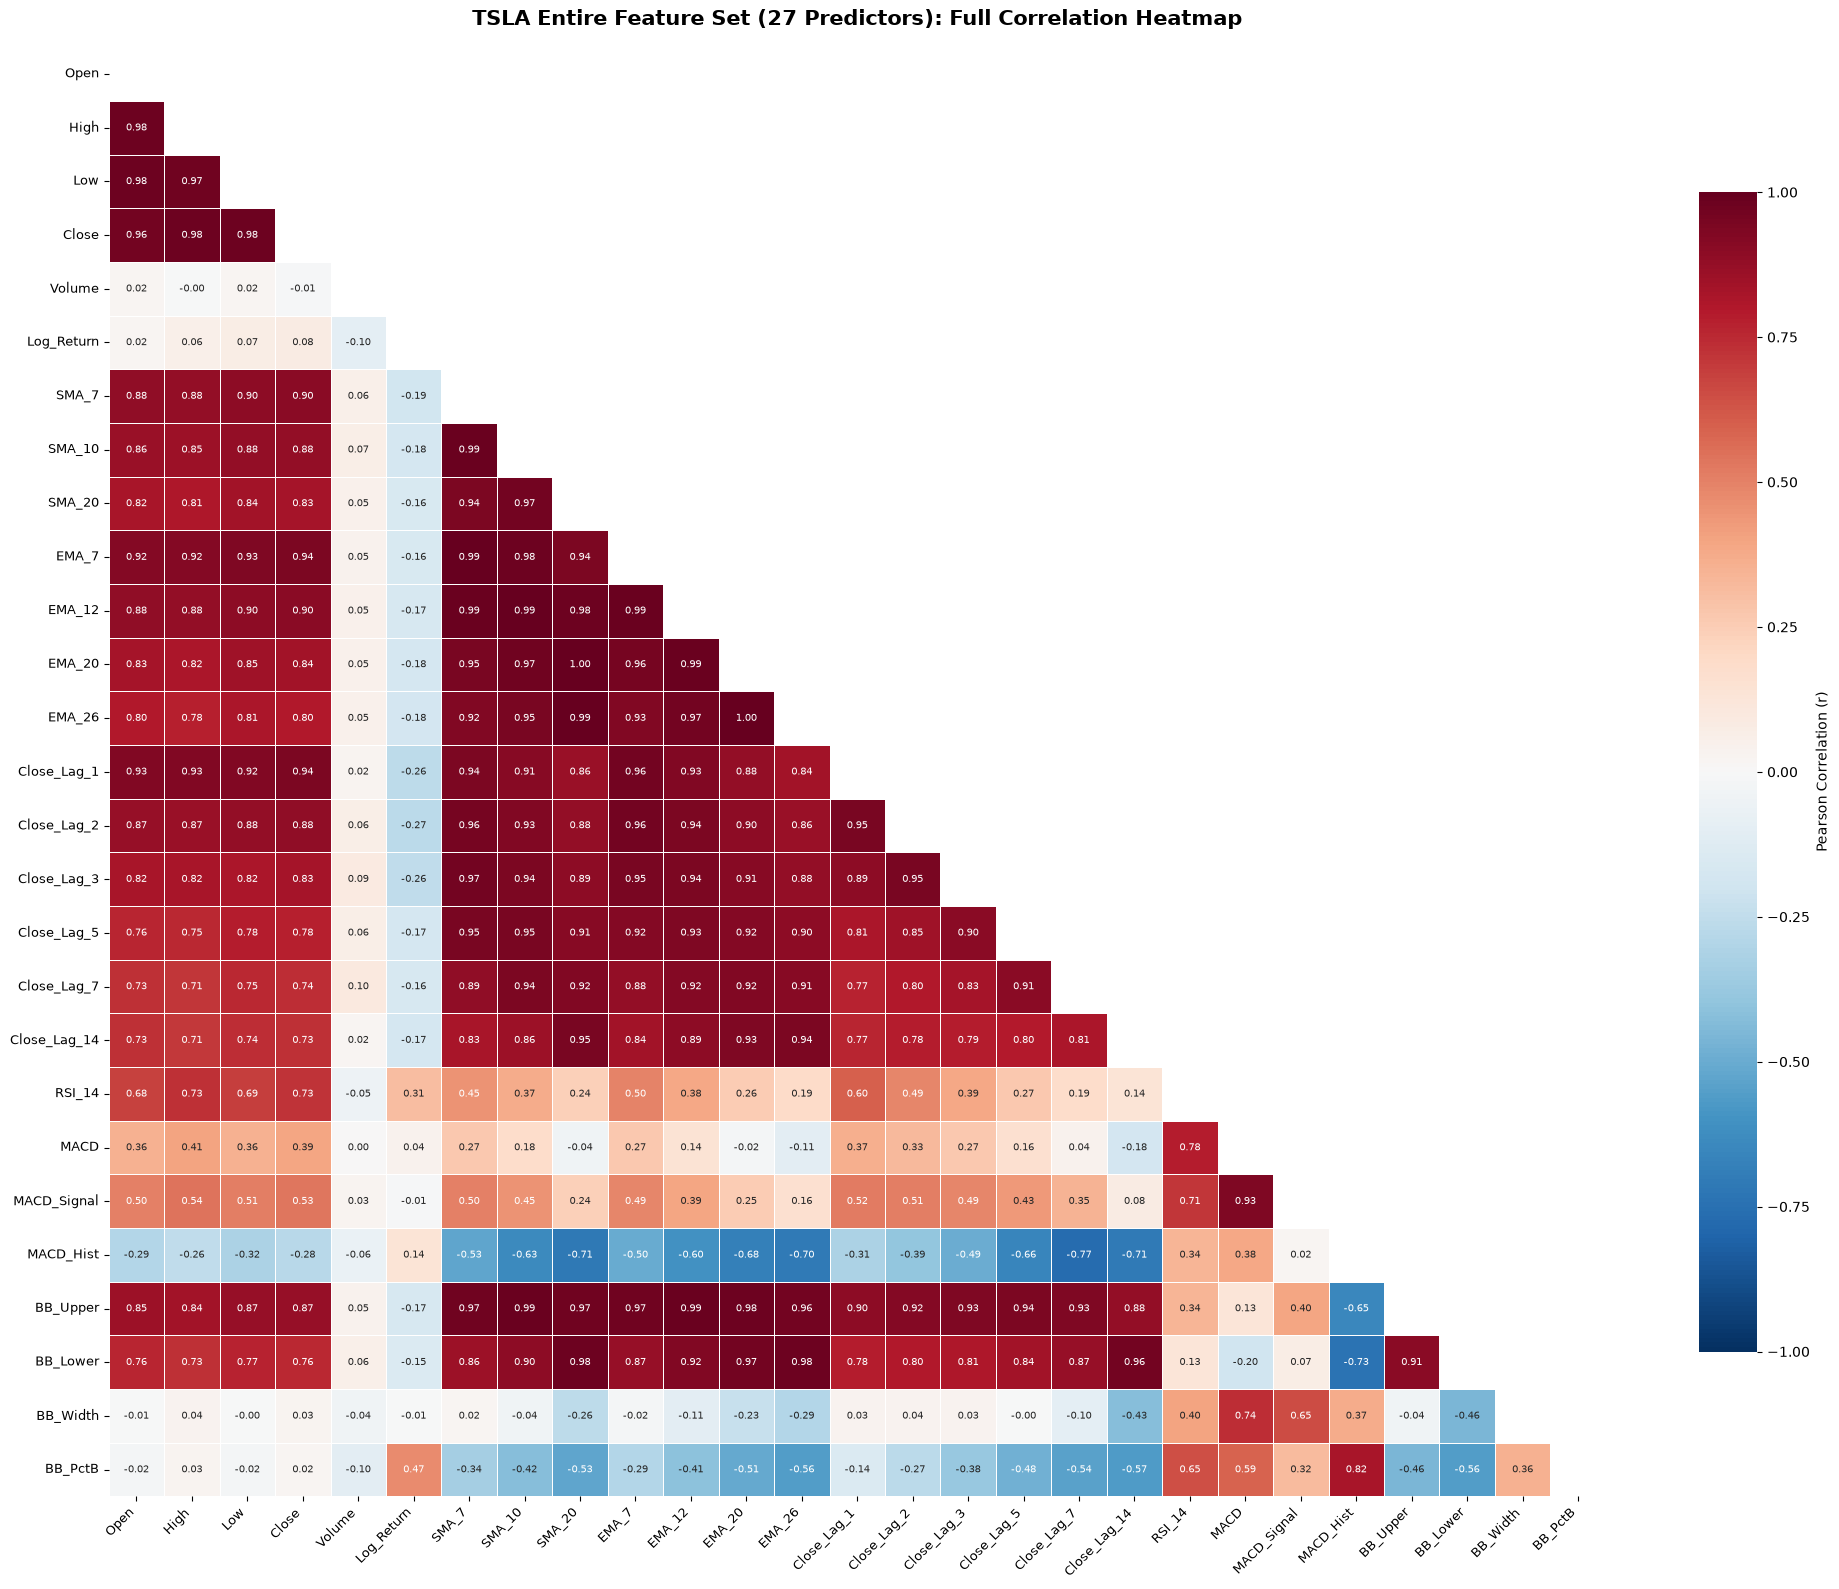

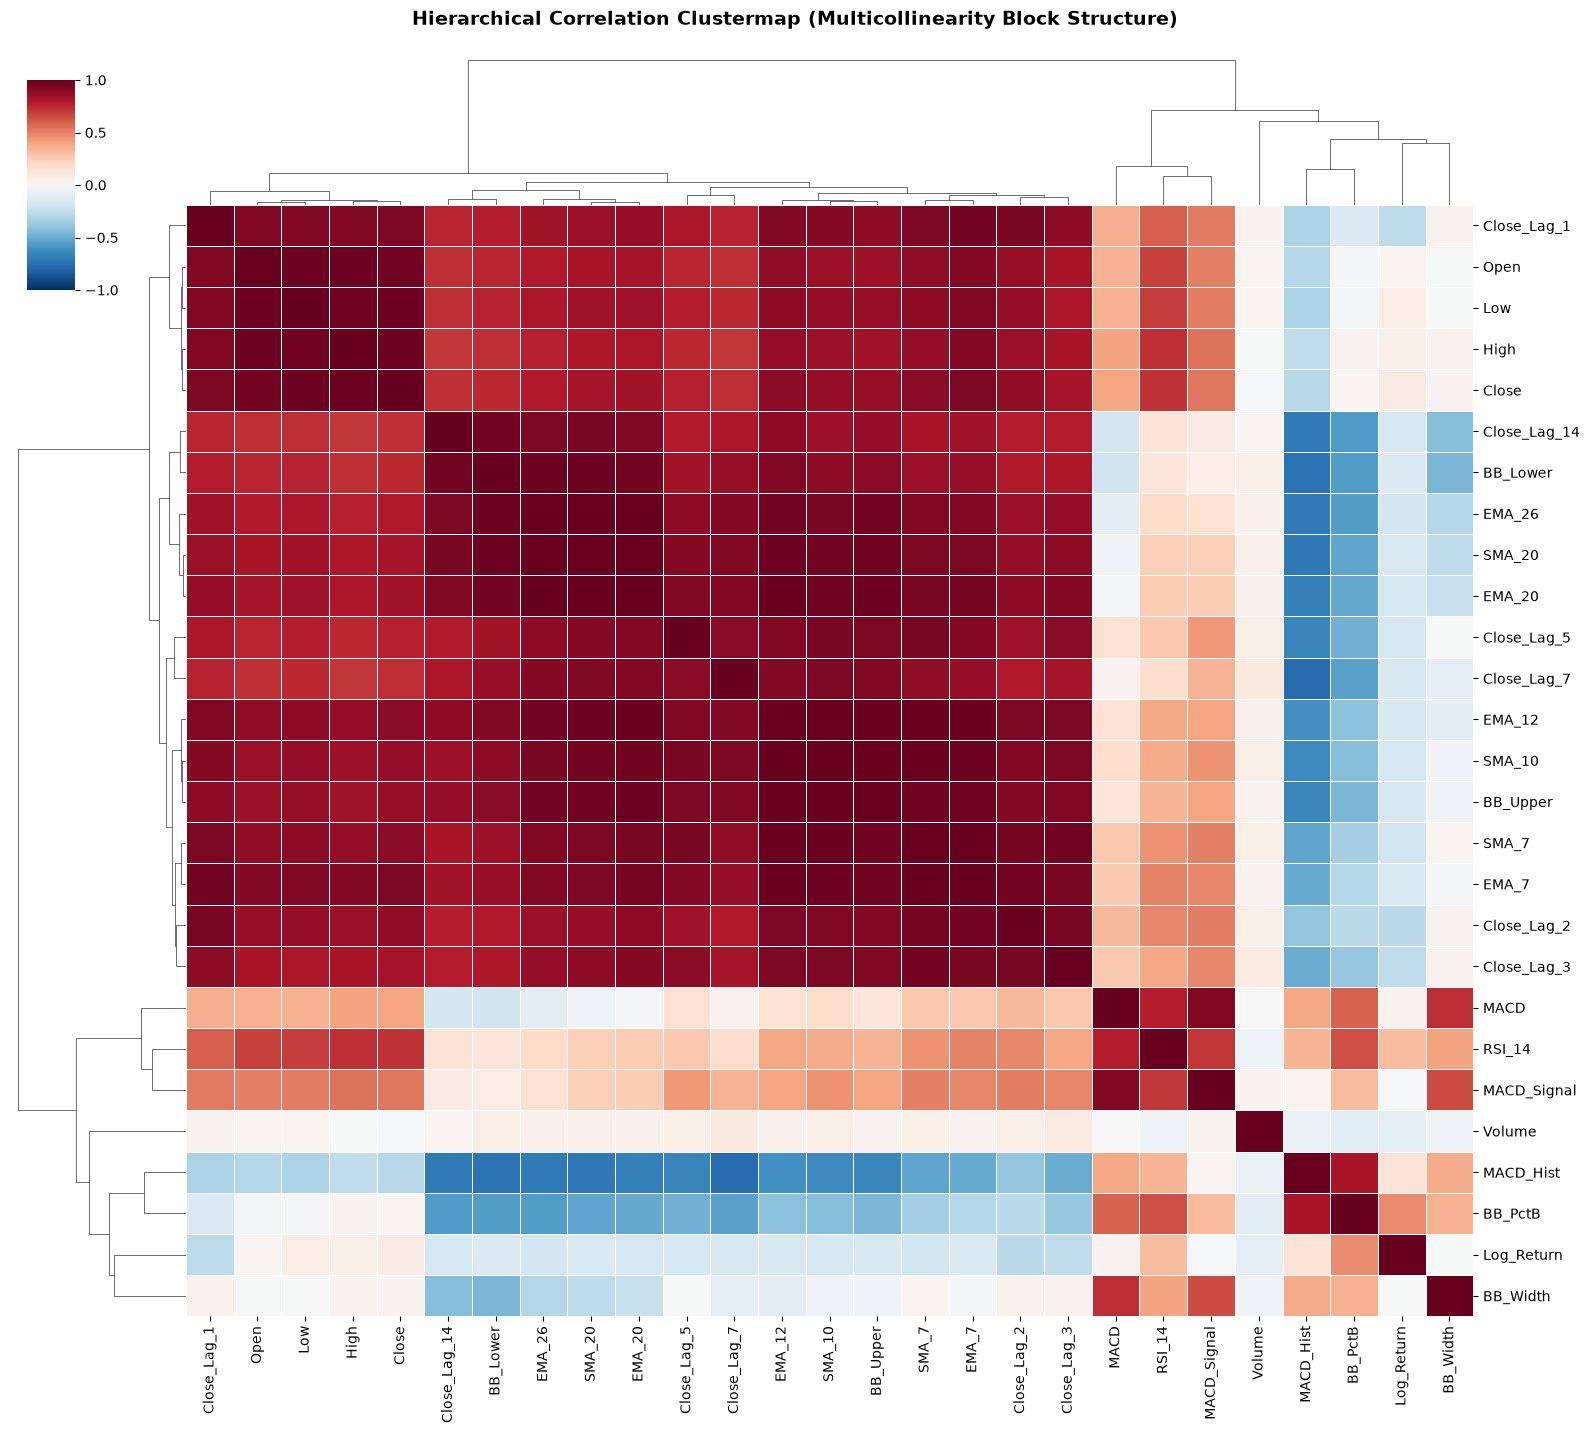

In [3]:
# 1. Full 27x27 Lower-Triangle Annotated Correlation Heatmap
plt.figure(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={'size': 7.5},
    cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'}
)
plt.title('TSLA Entire Feature Set (27 Predictors): Full Correlation Heatmap', fontsize=15, fontweight='bold', pad=16)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# 2. Hierarchical Clustermap (Groups Collinear Feature Clusters Automatically)
cg = sns.clustermap(
    corr_matrix,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    figsize=(16, 14),
    linewidths=0.4,
    dendrogram_ratio=(0.12, 0.12),
    cbar_pos=(0.02, 0.82, 0.03, 0.15)
)
cg.fig.suptitle('Hierarchical Correlation Clustermap (Multicollinearity Block Structure)', fontsize=14, fontweight='bold', y=1.02)
plt.show()